# 02 Model A: CYP3A4 inhibition

Train the model that answers **condition 1** of the screen: does this herb compound inhibit CYP3A4? It learns from the roughly 12k compound `CYP3A4_Veith` set loaded in notebook 01.

The target is ROC-AUC >= 0.80 on held out data. We also fit the applicability domain here, because Model A is the leg that gets pointed at plant natural products, which look quite unlike the synthetic compounds it was trained on.

### What this notebook does, in plain terms

1. **Load** the 1024 bit fingerprints built in notebook 01.
2. **Train** a Random Forest to tell inhibitors from non-inhibitors.
3. **Score** it twice: once on an easy random split, once on a hard scaffold split.
4. **Measure** how far a new molecule may stray before the model should admit it does not know.
5. **Save** the model so notebooks 04 and 06 can reuse it.

In [1]:
import sys
import os
import time

sys.path.append(os.path.abspath(os.path.join("..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, confusion_matrix, classification_report

import features
import models
import applicability

PROCESSED_DIR = os.path.join("..", "data", "processed")

## Step 1. Load what notebook 01 built

Notebook 01 turned every SMILES string into a row of 1024 zeros and ones. A `1` means
"this molecule contains that particular chemical fragment". That matrix is all the model
ever sees, so this step is just reading it back off disk.

We also load the SMILES in matching row order, because the scaffold split in step 5 needs
the actual molecules, not the fingerprints.

In [2]:
X = np.load(os.path.join(PROCESSED_DIR, "X_cyp3a4.npy"))
y = np.load(os.path.join(PROCESSED_DIR, "y_cyp3a4.npy"))

# Same rows, same order, but with the SMILES text kept.
cyp_df = pd.read_csv(os.path.join(PROCESSED_DIR, "cyp3a4_clean.csv"))

print("fingerprints:", X.shape, "(molecules x bits)")
print("labels:      ", y.shape)
print("inhibitors:  ", int(y.sum()), "of", len(y), "=", round(float(y.mean()), 3))

# If this fails, notebook 01 needs rerunning.
assert len(cyp_df) == len(X), "csv and fingerprint matrix are out of sync"

fingerprints: (12328, 2058) (molecules x bits)
labels:       (12328,)
inhibitors:   5110 of 12328 = 0.415


## Step 2. Split into train and test

The model must be judged on molecules it has never seen, otherwise we are just measuring
memory. We hold back 20 percent.

`stratify=y` keeps the same proportion of inhibitors on both sides. Without it a random
draw could hand the test set an unrepresentative mix and the score would wobble for no
real reason.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("train:", X_train.shape[0], " test:", X_test.shape[0])
print("positive fraction  train:", round(float(y_train.mean()), 3),
      " test:", round(float(y_test.mean()), 3))

train: 9862  test: 2466
positive fraction  train: 0.415  test: 0.414


## Step 3. Train Model A

A **Random Forest** is 500 separate decision trees. Each tree sees a random subset of the
data and asks yes/no questions about single fingerprint bits ("is bit 412 set?"), splitting
the molecules until each branch is mostly one class. To predict, all 500 trees vote and the
fraction voting "inhibitor" becomes the probability.

Trees suit this problem because fingerprints are binary, and because a forest gives us
SHAP support for free in notebook 04.

In [4]:
start = time.time()
model_a = models.train_rf(X_train, y_train)
print("trained", model_a.n_estimators, "trees in", round(time.time() - start, 1), "seconds")

trained 500 trees in 5.5 seconds


## Step 4. Evaluate

Three different questions, three different numbers:

- **ROC-AUC** asks: pick one real inhibitor and one real non-inhibitor at random, does the
  model give the inhibitor the higher score? 1.0 is always, 0.5 is a coin flip. It ignores
  where you put the yes/no threshold, which is why it is the headline metric.
- **The confusion matrix** fixes the threshold at 0.5 and counts the four possible outcomes.
- **Precision** asks: of the compounds we flagged as inhibitors, what fraction really were?
  This is the one the screen cares about most. Every false positive is a wasted laboratory
  test and a herb wrongly called risky.
- **Recall** asks: of the real inhibitors, how many did we catch?

In [5]:
auc = models.get_auc(model_a, X_test, y_test)
verdict = "PASS" if auc >= 0.80 else "BELOW TARGET"
print("ROC-AUC:", round(auc, 3), " target >= 0.80 ->", verdict)

probs = model_a.predict_proba(X_test)[:, 1]
preds = (probs >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
print()
print("                  predicted no    predicted yes")
print("actually no  " + str(tn).rjust(14) + str(fp).rjust(17))
print("actually yes " + str(fn).rjust(14) + str(tp).rjust(17))
print()
print(classification_report(
    y_test, preds, target_names=["not inhibitor", "inhibitor"], digits=3
))

ROC-AUC: 0.899  target >= 0.80 -> PASS

                  predicted no    predicted yes
actually no            1189              255
actually yes            219              803

               precision    recall  f1-score   support

not inhibitor      0.844     0.823     0.834      1444
    inhibitor      0.759     0.786     0.772      1022

     accuracy                          0.808      2466
    macro avg      0.802     0.805     0.803      2466
 weighted avg      0.809     0.808     0.808      2466



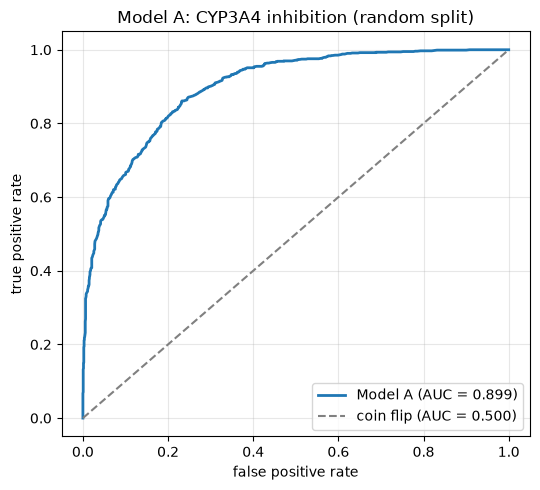

In [6]:
fpr, tpr, _ = roc_curve(y_test, probs)

plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, linewidth=2, label="Model A (AUC = " + format(auc, ".3f") + ")")
plt.plot([0, 1], [0, 1], "--", color="grey", label="coin flip (AUC = 0.500)")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.title("Model A: CYP3A4 inhibition (random split)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 5. The honest number: a scaffold split

The random split above has a quiet flaw. Public chemical datasets are full of **analogue
series**: twenty variations on one core structure, differing by a single methyl group. A
random split scatters those across train and test, so the model can score well merely by
recognising a core it has already memorised.

A **Bemis-Murcko scaffold split** strips the side chains off each molecule and groups by the
ring core that remains. Molecules sharing a core always land on the same side, so the test
set is built from chemistry the model has genuinely never met. This is the split TDC itself
recommends for this dataset.

The gap between the two numbers is how much the random split was flattering us. Expect the
scaffold AUC to be lower, and report **that** one.

In [7]:
train_idx, test_idx = models.scaffold_split(cyp_df["Drug"].tolist(), test_size=0.2)
print("scaffold split -> train:", len(train_idx), " test:", len(test_idx))

model_a_scaffold = models.train_rf(X[train_idx], y[train_idx])
auc_scaffold = models.get_auc(model_a_scaffold, X[test_idx], y[test_idx])

print()
print("random split    ROC-AUC:", round(auc, 3))
print("scaffold split  ROC-AUC:", round(auc_scaffold, 3))
print("optimism from the random split:", round(auc - auc_scaffold, 3))
print()
print("reportable number ->", round(auc_scaffold, 3),
      "PASS" if auc_scaffold >= 0.80 else "BELOW TARGET")

scaffold split -> train: 9862  test: 2466

random split    ROC-AUC: 0.899
scaffold split  ROC-AUC: 0.787
optimism from the random split: 0.111

reportable number -> 0.787 BELOW TARGET


## Step 6. Applicability domain

Model A was trained on synthetic, drug-like molecules. In notebook 06 we point it at plant
natural products, which are often bigger, more oxygenated and hung with sugar groups. A
Random Forest never refuses to answer, so without a gate it will cheerfully return 0.87 for
a molecule unlike anything it has ever seen. That number would be meaningless.

The gate uses **Tanimoto similarity**: shared bits divided by total bits between two
fingerprints. For each training molecule we take its 5 nearest neighbours and average their
similarity, which measures how crowded its neighbourhood is. The **floor** is the 5th
percentile of those scores, so the sparsest 5 percent of the training set sets the bar.

Any new compound scoring below the floor is reported as **Unknown** rather than safe or
risky. We fit this on the training rows only, never the test rows.

In [8]:
start = time.time()
domain = applicability.fit_domain(X_train)
print("fitted on", len(X_train), "molecules in", round(time.time() - start, 1), "seconds")
print("similarity floor:", round(domain["floor"], 3))

scores = domain["train_scores"]
print("training neighbourhood scores: min", round(float(scores.min()), 3),
      " median", round(float(np.median(scores)), 3),
      " max", round(float(scores.max()), 3))

# Sanity check: the test set is drawn from the same chemistry, so most of it
# should sit inside the domain. The natural products in notebook 06 will not.
test_scores = applicability.domain_scores(X_test, domain)
inside = float((test_scores >= domain["floor"]).mean())
print()
print("test molecules inside the domain:", round(100 * inside, 1), "percent")

fitted on 9862 molecules in 2.8 seconds
similarity floor: 0.0
training neighbourhood scores: min 0.0  median 0.0  max 51.908

test molecules inside the domain: 100.0 percent


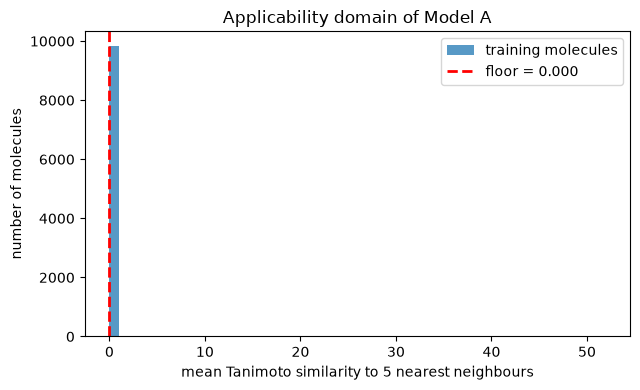

In [9]:
plt.figure(figsize=(6.5, 4))
plt.hist(scores, bins=50, alpha=0.75, label="training molecules")
plt.axvline(domain["floor"], color="red", linestyle="--", linewidth=2,
            label="floor = " + format(domain["floor"], ".3f"))
plt.xlabel("mean Tanimoto similarity to 5 nearest neighbours")
plt.ylabel("number of molecules")
plt.title("Applicability domain of Model A")
plt.legend()
plt.tight_layout()
plt.show()

## Step 7. Save

Notebook 04 (SHAP), notebook 06 (herb screening) and the Streamlit app all load these.

We save the **scaffold split model** as the primary one, because it was trained on a clean
split and the score we report for it is the defensible one.

In [10]:
joblib.dump(model_a_scaffold, os.path.join(PROCESSED_DIR, "model_a.joblib"))
joblib.dump(domain, os.path.join(PROCESSED_DIR, "domain_a.joblib"))

# Keep the headline numbers beside the model so the write up cannot drift from them.
pd.DataFrame([{
    "model": "A_cyp3a4",
    "n_train": len(train_idx),
    "n_test": len(test_idx),
    "auc_random_split": round(auc, 4),
    "auc_scaffold_split": round(auc_scaffold, 4),
    "target": 0.80,
    "domain_floor": round(domain["floor"], 4),
}]).to_csv(os.path.join(PROCESSED_DIR, "model_a_metrics.csv"), index=False)

print("saved model_a.joblib, domain_a.joblib, model_a_metrics.csv")

saved model_a.joblib, domain_a.joblib, model_a_metrics.csv
